# 02 · EDA y validación de fuentes

**Fase: Find the truth.** Usa las tablas limpias que genera `01_calidad_y_limpieza.ipynb` (correr ese primero).

Contenido:
1. ¿Qué fuente de precios es confiable?
2. Rendimiento y riesgo por activo
3. Diversificación (correlaciones)
4. Contexto macro y tipo de cambio
5. Fundamentales
6. Eventos y reacción del precio
7. Historia larga 2020–2026
8. Implicaciones por tipo de cliente

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.figsize': (11, 4.5), 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .3})

CLEAN = Path('../data_clean')
prices = pd.read_csv(CLEAN / 'prices_daily.csv', parse_dates=['date'])
exp_daily = pd.read_csv(CLEAN / 'prices_expanded_daily.csv', parse_dates=['date'])
macro = pd.read_csv(CLEAN / 'macro.csv', parse_dates=['date']).set_index('date')
fund = pd.read_csv(CLEAN / 'fundamentals.csv', parse_dates=['period_end'])
ref = pd.read_csv(CLEAN / 'asset_reference.csv')
clients = pd.read_csv(CLEAN / 'client_profiles.csv')
events = pd.read_csv(CLEAN / 'events.csv', parse_dates=['event_date'])

ASSETS = sorted(prices.asset_id.unique())
NAME = dict(zip(ref.asset_id, ref.asset_id.str[3:] + ' ' + ref.name))
close = prices.pivot(index='date', columns='asset_id', values='close')
ret = close.pct_change()
close_exp = exp_daily.pivot(index='date', columns='asset_id', values='close_exp')

## 1. ¿Qué fuente de precios es confiable?
El archivo diario y el expanded no coinciden. Para decidir cuál creer se contrastan con dos fuentes independientes:
- **Factor de mercado** de la tabla macro: los retornos de acciones reales se mueven con el mercado.
- **Eventos**: una noticia negativa de severidad alta debería verse como caída en el precio.

In [2]:
exp_recent = close_exp.loc[close.index]
ret_exp = exp_recent.pct_change()
corr_mkt = pd.DataFrame({
    'diario': ret.corrwith(macro.market_factor),
    'expanded': ret_exp.corrwith(macro.market_factor),
}).round(2)
display(corr_mkt.T.assign(promedio=corr_mkt.mean().round(2)))

asset_id,VF_A01,VF_A02,VF_A03,VF_A04,VF_A05,VF_A06,VF_A07,VF_A08,promedio
diario,0.28,0.43,0.41,0.49,0.44,0.46,0.37,0.29,0.40
expanded,0.13,0.14,0.05,0.07,0.03,0.12,0.12,0.19,0.11


In [3]:
sector_asset = dict(zip(ref.sector, ref.asset_id))

def event_reaction(series, date, days=5):
    i = series.index.searchsorted(date)
    prev = series.iloc[i - 1]
    return (series.iloc[i] / prev - 1) * 100, (series.iloc[min(i + days, len(series) - 1)] / prev - 1) * 100

rows = []
for _, ev in events.iterrows():
    a = ev.scope if ev.scope in ASSETS else sector_asset[ev.scope]
    d_day, d_5 = event_reaction(close[a], ev.event_date)
    _, e_5 = event_reaction(exp_recent[a], ev.event_date)
    rows.append({'fecha': ev.event_date.date(), 'activo': a, 'severidad': ev.severity, 'titular': ev.headline,
                 'diario_día_%': round(d_day, 1), 'diario_5d_%': round(d_5, 1), 'expanded_5d_%': round(e_5, 1)})
ev_react = pd.DataFrame(rows)
ev_react

,fecha,activo,severidad,titular,diario_día_%,diario_5d_%,expanded_5d_%
0,2026-02-10,VF_A02,High,Interrupción temporal de un proveedor crítico ...,1.0,-17.9,-5.0
1,2026-04-06,VF_A03,Medium,Mejora abrupta en margen de referencia energético,3.0,5.9,-5.3
2,2026-05-18,VF_A04,Medium,Resultados superan expectativas internas del m...,-0.0,-0.7,-2.0
3,2026-06-08,VF_A07,High,Debilidad inesperada en demanda externa del se...,-0.8,-10.3,-3.4
4,2026-07-21,VF_A02,Medium,Repricing de múltiplos en compañías de crecimi...,-1.8,-5.3,3.3


**Conclusión:** el diario se mueve con el factor de mercado (correlación ≈ 0.4) y reacciona a las noticias en la dirección esperada; el expanded casi no se relaciona con el mercado (≈ 0.1) y en dos eventos va al revés. **Fuente de verdad: archivo diario.** El expanded solo se usa como contexto histórico 2020–2025.

Limitación: tras los resultados positivos de Lima Financial el precio casi no se mueve.

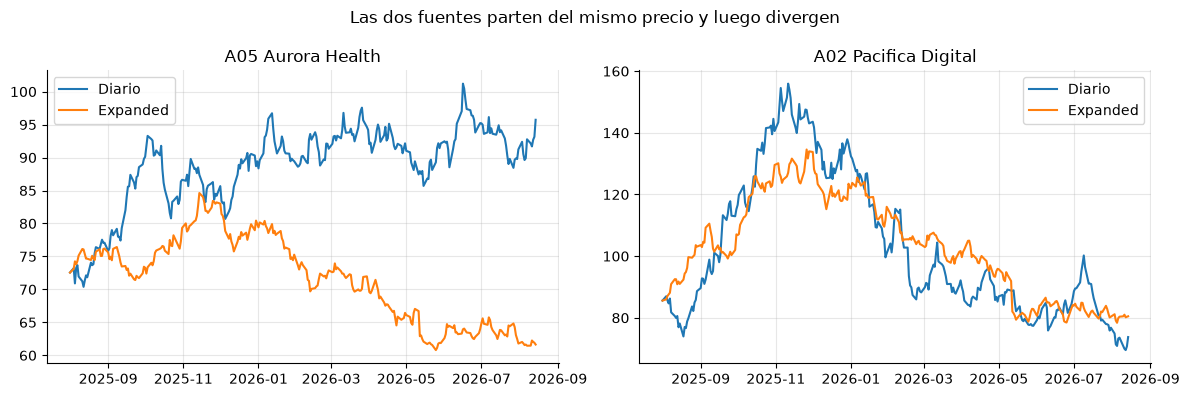

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, a in zip(axes, ['VF_A05', 'VF_A02']):
    ax.plot(close.index, close[a], label='Diario')
    ax.plot(exp_recent.index, exp_recent[a], label='Expanded')
    ax.set_title(NAME[a]); ax.legend()
plt.suptitle('Las dos fuentes parten del mismo precio y luego divergen'); plt.tight_layout()

## 2. Rendimiento y riesgo por activo
Precios en base 100 al primer día, con los periodos Stress (rojo) y Recovery (verde) de la tabla macro.

Text(0.5, 0, '')

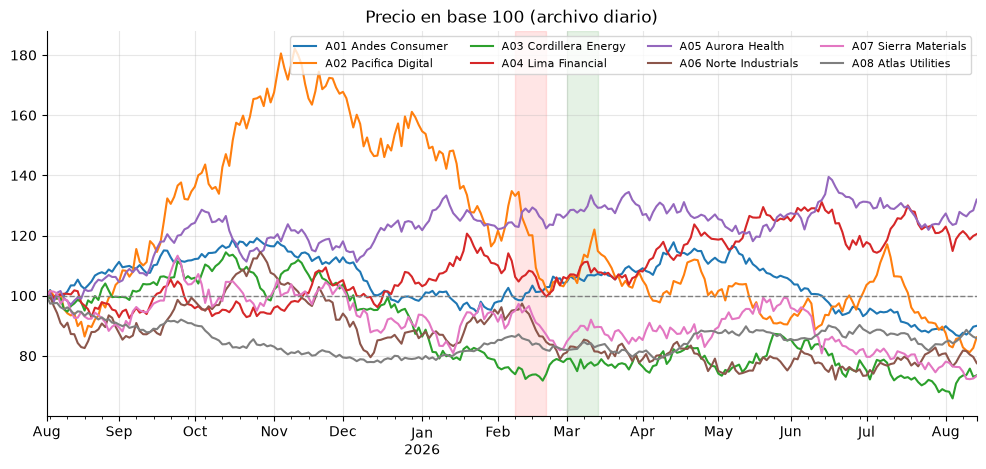

In [5]:
def shade_regimes(ax):
    reg = macro.risk_regime
    for k, color in [('Stress', 'red'), ('Recovery', 'green')]:
        on = reg.eq(k)
        for _, block in reg[on].groupby((~on).cumsum()[on]):
            ax.axvspan(block.index[0], block.index[-1], color=color, alpha=.1)

base100 = close / close.iloc[0] * 100
ax = base100.rename(columns=NAME).plot(figsize=(12, 5), lw=1.5)
shade_regimes(ax); ax.axhline(100, color='grey', ls='--', lw=1)
ax.set_title('Precio en base 100 (archivo diario)'); ax.legend(ncol=4, fontsize=8); ax.set_xlabel('')

In [6]:
def max_drawdown(s):
    return (s / s.cummax() - 1).min()

mf = macro.market_factor
stress = macro.risk_regime.eq('Stress')
metrics = pd.DataFrame({
    'retorno_%': (close.iloc[-1] / close.iloc[0] - 1) * 100,
    'vol_anual_%': ret.std() * np.sqrt(252) * 100,
    'caída_máx_%': close.apply(max_drawdown) * 100,
    'beta': ret.apply(lambda s: s.cov(mf) / mf.var()),
    'retorno_en_stress_%': ret[stress].sum() * 100,
    'volumen_prom_M': prices.groupby('asset_id').volume.mean() / 1e6,
})
metrics['sharpe_aprox'] = metrics['retorno_%'] / metrics['vol_anual_%']
metrics = ref.set_index('asset_id')[['name', 'sector', 'country']].join(metrics.round(2))
metrics.sort_values('retorno_%', ascending=False)

,name,sector,country,retorno_%,vol_anual_%,caída_máx_%,beta,retorno_en_stress_%,volumen_prom_M,sharpe_aprox
asset_id,,,,,,,,,,
VF_A05,Aurora Health,Health Care,United States,31.93,23.98,-13.51,0.80,-1.50,1.82,1.33
VF_A04,Lima Financial,Financials,Peru,20.47,28.25,-17.39,1.05,-11.06,1.77,0.72
VF_A01,Andes Consumer,Consumer Staples,Colombia,-10.03,20.07,-27.36,0.42,2.72,1.86,-0.50
VF_A02,Pacifica Digital,Technology,Peru,-13.82,45.15,-55.41,1.46,-26.95,1.70,-0.31
VF_A08,Atlas Utilities,Utilities,United States,-14.16,15.43,-22.24,0.34,-5.48,1.87,-0.92
VF_A06,Norte Industrials,Industrials,Mexico,-22.43,33.53,-37.05,1.18,-11.43,1.76,-0.67
VF_A03,Cordillera Energy,Energy,Colombia,-26.48,34.93,-42.46,1.08,-1.07,1.87,-0.76
VF_A07,Sierra Materials,Materials,Chile,-26.68,38.32,-36.24,1.08,-7.69,1.87,-0.70


Text(0.5, 1.0, 'Retorno vs. volatilidad')

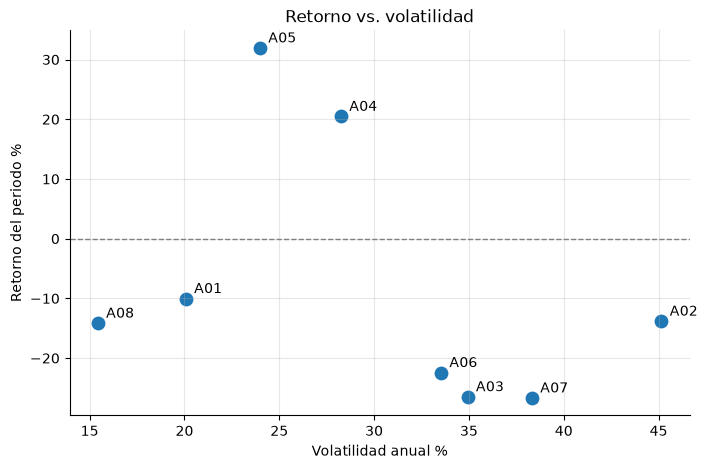

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(metrics['vol_anual_%'], metrics['retorno_%'], s=80)
for a, r in metrics.iterrows():
    ax.annotate(a[3:], (r['vol_anual_%'], r['retorno_%']), xytext=(6, 4), textcoords='offset points')
ax.axhline(0, color='grey', ls='--', lw=1)
ax.set_xlabel('Volatilidad anual %'); ax.set_ylabel('Retorno del periodo %'); ax.set_title('Retorno vs. volatilidad')

Arriba a la izquierda es mejor. A05 y A04 son los únicos con retorno positivo; A02 es el más volátil y el más golpeado en el Stress de febrero.

### Distribución de retornos diarios
Colas gordas o días extremos indican riesgo que la volatilidad sola no muestra.

Días con |retorno| > 5% por activo: {'VF_A02': 19, 'VF_A07': 14, 'VF_A03': 7, 'VF_A06': 5, 'VF_A04': 1}


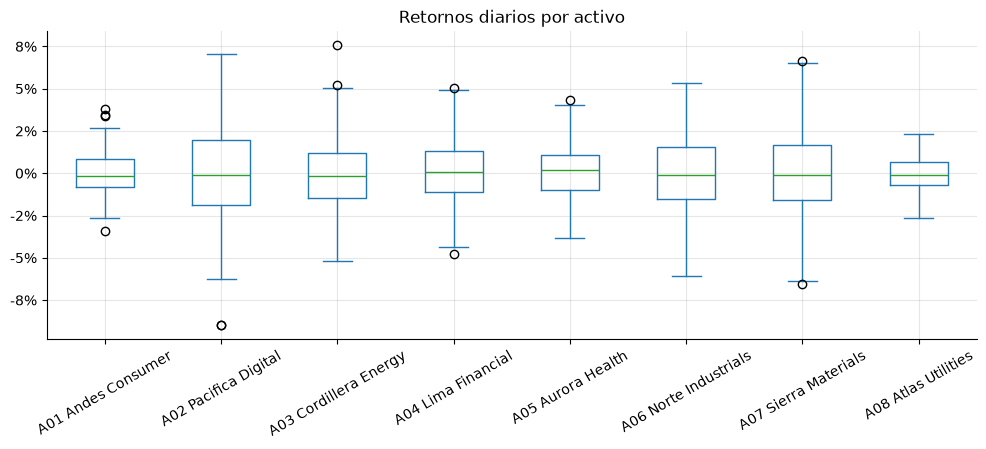

In [8]:
ax = ret.rename(columns=NAME).plot(kind='box', figsize=(12, 4), rot=30)
ax.set_title('Retornos diarios por activo'); ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
extremos = ret.stack()[ret.stack().abs() > .05].rename('retorno').reset_index()
print('Días con |retorno| > 5% por activo:', extremos.asset_id.value_counts().to_dict())

## 3. Diversificación

Correlación entre pares: min -0.01, máx 0.26, promedio 0.16


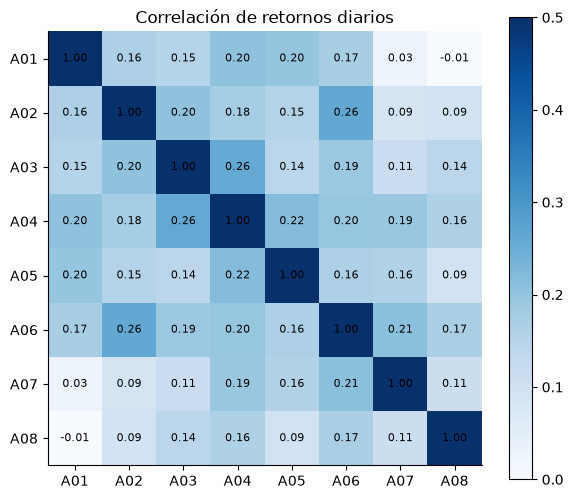

In [9]:
corr = ret.corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap='Blues', vmin=0, vmax=.5)
ax.set_xticks(range(len(ASSETS)), [a[3:] for a in ASSETS]); ax.set_yticks(range(len(ASSETS)), [a[3:] for a in ASSETS])
for i in range(len(ASSETS)):
    for j in range(len(ASSETS)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
ax.grid(False); plt.colorbar(im); ax.set_title('Correlación de retornos diarios')
off = corr.where(~np.eye(len(corr), dtype=bool)).stack()
print(f'Correlación entre pares: min {off.min():.2f}, máx {off.max():.2f}, promedio {off.mean():.2f}')

Todas las correlaciones están por debajo de 0.3, así que combinar activos reduce bastante la volatilidad del portafolio. Ejemplo con un portafolio de igual peso:

In [10]:
ew = ret.mean(axis=1)
ew_curve = (1 + ew.fillna(0)).cumprod()
print(f'Igual peso → vol anual {ew.std() * np.sqrt(252) * 100:.1f}%, caída máx {max_drawdown(ew_curve) * 100:.1f}%')
print(f'Promedio de la vol individual: {metrics["vol_anual_%"].mean():.1f}%')

Igual peso → vol anual 15.8%, caída máx -19.3%
Promedio de la vol individual: 30.0%


## 4. Contexto macro y tipo de cambio

,cambio_%,vol_anual_%
usd_cop,2.56,5.54
usd_pen,-1.16,2.78
usd_mxn,-1.15,3.74
usd_clp,7.17,4.63


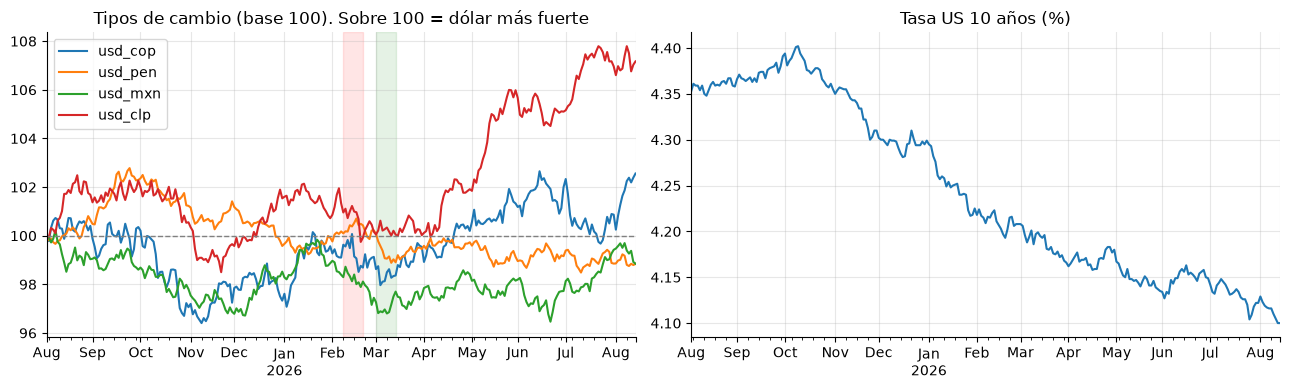

In [11]:
fx = macro[['usd_cop', 'usd_pen', 'usd_mxn', 'usd_clp']]
fx100 = fx / fx.iloc[0] * 100
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fx100.plot(ax=axes[0]); shade_regimes(axes[0]); axes[0].axhline(100, color='grey', ls='--', lw=1)
axes[0].set_title('Tipos de cambio (base 100). Sobre 100 = dólar más fuerte')
macro.us_10y_yield.plot(ax=axes[1]); axes[1].set_title('Tasa US 10 años (%)')
for a in axes: a.set_xlabel('')
plt.tight_layout()
pd.DataFrame({'cambio_%': (fx.iloc[-1] / fx.iloc[0] - 1) * 100, 'vol_anual_%': fx.pct_change().std() * np.sqrt(252) * 100}).round(2)

Para un cliente que mide en COP o PEN, el retorno en su moneda es aproximadamente `(1 + r_USD) × (1 + Δ tipo de cambio) − 1`. El dólar subió frente al COP (ayuda a Patrimonio Estable) y bajó un poco frente al PEN (resta a Diversificación Regional).

In [12]:
ret_local = pd.DataFrame({
    'USD': metrics['retorno_%'],
    'COP': ((1 + metrics['retorno_%'] / 100) * (fx.usd_cop.iloc[-1] / fx.usd_cop.iloc[0]) - 1) * 100,
    'PEN': ((1 + metrics['retorno_%'] / 100) * (fx.usd_pen.iloc[-1] / fx.usd_pen.iloc[0]) - 1) * 100,
}).round(1)
ret_local

,USD,COP,PEN
asset_id,,,
VF_A01,-10.0,-7.7,-11.1
VF_A02,-13.8,-11.6,-14.8
VF_A03,-26.5,-24.6,-27.3
VF_A04,20.5,23.6,19.1
VF_A05,31.9,35.3,30.4
VF_A06,-22.4,-20.4,-23.3
VF_A07,-26.7,-24.8,-27.5
VF_A08,-14.2,-12.0,-15.2


In [13]:
regime_ret = ret.join(macro.risk_regime).groupby('risk_regime').mean() * 100
regime_ret.T.round(2).rename(columns=lambda c: f'ret_diario_prom_{c}_%')

risk_regime,ret_diario_prom_Normal_%,ret_diario_prom_Recovery_%,ret_diario_prom_Stress_%
VF_A01,-0.06,0.30,0.27
VF_A02,0.05,1.14,-2.69
VF_A03,-0.09,-0.05,-0.11
VF_A04,0.13,0.16,-1.11
VF_A05,0.12,0.27,-0.15
VF_A06,-0.04,0.11,-1.14
VF_A07,-0.10,0.85,-0.77
VF_A08,-0.04,0.17,-0.55


## 5. Fundamentales

In [14]:
fund = fund.sort_values(['issuer_id', 'period_end'])
fund['margen_ebitda_%'] = fund.ebitda_usd_m / fund.revenue_usd_m * 100
fund['margen_neto_%'] = fund.net_income_usd_m / fund.revenue_usd_m * 100
fund['ebitda_12m'] = fund.groupby('issuer_id').ebitda_usd_m.transform(lambda s: s.rolling(4).sum())
fund['deuda_neta_ebitda'] = (fund.debt_usd_m - fund.cash_usd_m) / fund.ebitda_12m
fund['crec_ingresos_anual_%'] = fund.groupby('issuer_id').revenue_usd_m.pct_change(4) * 100

last = fund.groupby('issuer_id').tail(1).merge(ref[['issuer_id', 'asset_id', 'name']], on='issuer_id')
last.assign(period_end=last.period_end.dt.date)[['issuer_id', 'asset_id', 'name', 'period_end', 'revenue_usd_m', 'crec_ingresos_anual_%',
      'margen_ebitda_%', 'margen_neto_%', 'deuda_neta_ebitda']].round(2)

,issuer_id,asset_id,name,period_end,revenue_usd_m,crec_ingresos_anual_%,margen_ebitda_%,margen_neto_%,deuda_neta_ebitda
0,ISS_01,VF_A01,Andes Consumer,2026-06-30,2229.3,6.78,33.27,22.47,0.27
1,ISS_02,VF_A02,Pacifica Digital,2026-06-30,3221.6,10.01,27.20,13.79,0.23
2,ISS_03,VF_A03,Cordillera Energy,2026-06-30,3397.8,4.70,11.95,7.38,0.01
3,ISS_04,VF_A04,Lima Financial,2026-06-30,4665.5,10.01,30.42,20.12,0.29
4,ISS_05,VF_A05,Aurora Health,2026-06-30,2149.5,9.07,28.36,20.36,0.31
5,ISS_06,VF_A06,Norte Industrials,2026-06-30,3106.5,9.16,16.01,7.77,0.68
6,ISS_07,VF_A07,Sierra Materials,2026-06-30,5460.9,8.73,21.14,13.42,0.12
7,ISS_08,VF_A08,Atlas Utilities,2026-06-30,2086.8,3.66,12.35,7.70,-0.24


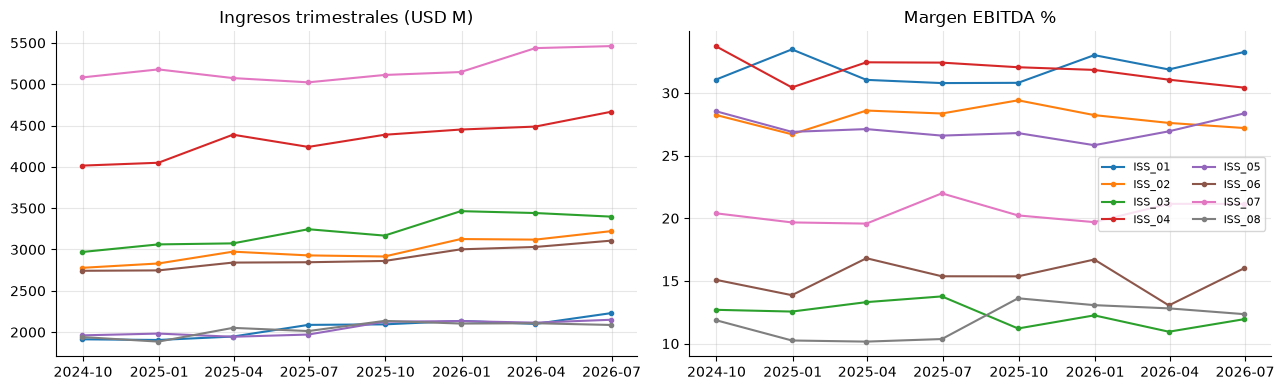

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for iss, g in fund.groupby('issuer_id'):
    axes[0].plot(g.period_end, g.revenue_usd_m, marker='o', ms=3, label=iss)
    axes[1].plot(g.period_end, g['margen_ebitda_%'], marker='o', ms=3, label=iss)
axes[0].set_title('Ingresos trimestrales (USD M)'); axes[1].set_title('Margen EBITDA %')
axes[1].legend(ncol=2, fontsize=8); plt.tight_layout()

Todos los emisores tienen poca deuda (deuda neta / EBITDA < 1). Los más rentables son ISS_01 e ISS_04; los menos, ISS_03 e ISS_08. ¿Los fundamentales explican el precio?

In [16]:
cruce = metrics[['retorno_%', 'vol_anual_%']].join(last.set_index('asset_id')[['margen_ebitda_%', 'crec_ingresos_anual_%', 'deuda_neta_ebitda']])
display(cruce.round(2))
print(cruce.corr().loc[['margen_ebitda_%', 'crec_ingresos_anual_%', 'deuda_neta_ebitda'], 'retorno_%'].round(2))

,retorno_%,vol_anual_%,margen_ebitda_%,crec_ingresos_anual_%,deuda_neta_ebitda
asset_id,,,,,
VF_A01,-10.03,20.07,33.27,6.78,0.27
VF_A02,-13.82,45.15,27.20,10.01,0.23
VF_A03,-26.48,34.93,11.95,4.70,0.01
VF_A04,20.47,28.25,30.42,10.01,0.29
VF_A05,31.93,23.98,28.36,9.07,0.31
VF_A06,-22.43,33.53,16.01,9.16,0.68
VF_A07,-26.68,38.32,21.14,8.73,0.12
VF_A08,-14.16,15.43,12.35,3.66,-0.24


margen_ebitda_%          0.61
crec_ingresos_anual_%    0.39
deuda_neta_ebitda        0.18
Name: retorno_%, dtype: float64


El margen EBITDA tiene la relación más clara con el retorno (correlación ≈ 0.6): A04 y A05, los dos únicos activos que suben, están entre los más rentables. Pero son solo ocho puntos y A01 tiene el mayor margen con retorno negativo, así que es una señal de apoyo, no una regla.

## 6. Eventos y reacción del precio

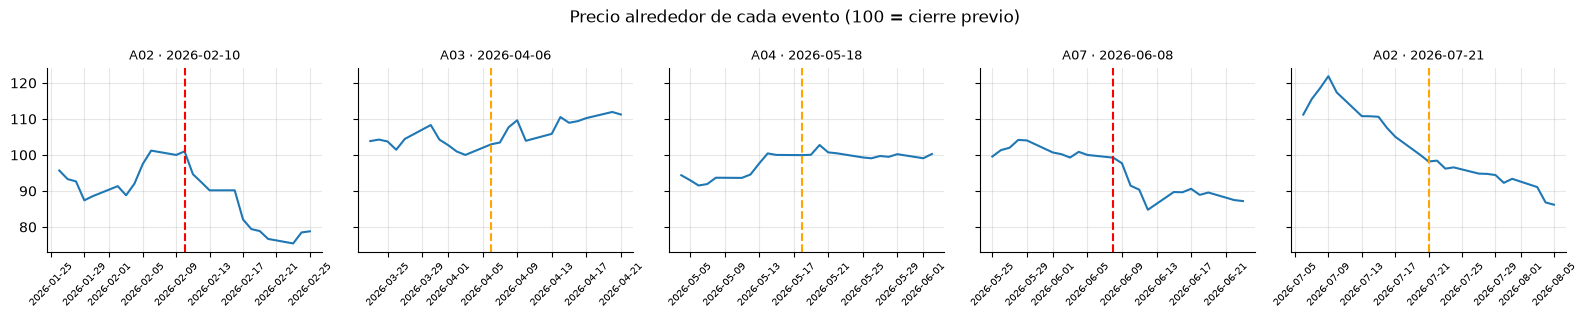

In [17]:
fig, axes = plt.subplots(1, len(ev_react), figsize=(16, 3.2), sharey=True)
for ax, (_, ev) in zip(axes, ev_react.iterrows()):
    d = pd.Timestamp(ev.fecha)
    win = base100[ev.activo].loc[d - pd.Timedelta(days=15): d + pd.Timedelta(days=15)]
    ax.plot(win.index, win / win.loc[:d].iloc[-2] * 100)
    ax.axvline(d, color='red' if ev.severidad == 'High' else 'orange', ls='--')
    ax.set_title(f'{ev.activo[3:]} · {ev.fecha}', fontsize=9); ax.tick_params(axis='x', labelrotation=45, labelsize=7)
plt.suptitle('Precio alrededor de cada evento (100 = cierre previo)'); plt.tight_layout()

## 7. Historia larga 2020–2026 (expanded, solo como contexto)

,vol_anual_%,caída_máx_%
asset_id,,
VF_A01,24.7,-59.1
VF_A02,34.8,-80.3
VF_A03,30.0,-81.8
VF_A04,25.5,-51.2
VF_A05,21.7,-69.0
VF_A06,29.2,-56.1
VF_A07,32.4,-75.6
VF_A08,17.4,-57.4


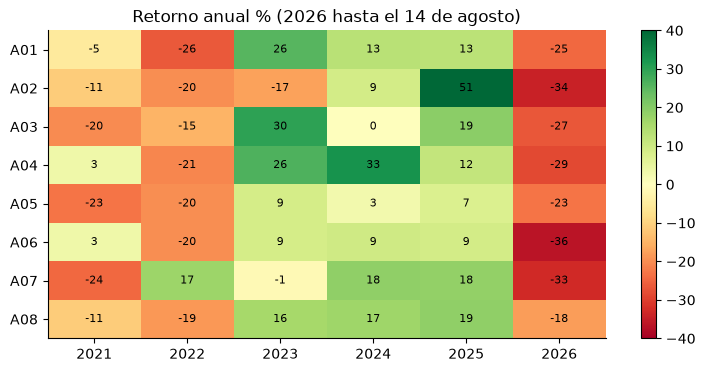

In [18]:
yearly = close_exp.groupby(close_exp.index.year).last().pct_change().iloc[1:] * 100
fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(yearly.T, cmap='RdYlGn', vmin=-40, vmax=40, aspect='auto')
ax.set_yticks(range(len(ASSETS)), [a[3:] for a in yearly.columns]); ax.set_xticks(range(len(yearly)), yearly.index)
for i in range(yearly.shape[1]):
    for j in range(yearly.shape[0]):
        ax.text(j, i, f'{yearly.iloc[j, i]:.0f}', ha='center', va='center', fontsize=8)
ax.grid(False); plt.colorbar(im); ax.set_title('Retorno anual % (2026 hasta el 14 de agosto)')
hist = pd.DataFrame({'vol_anual_%': close_exp.pct_change().std() * np.sqrt(252) * 100,
                     'caída_máx_%': close_exp.apply(max_drawdown) * 100}).round(1)
hist

## 8. Implicaciones por tipo de cliente

In [19]:
display(clients)
lim = clients.set_index('client_id').max_drawdown_tolerance_pct
check = metrics[['name', 'caída_máx_%', 'vol_anual_%', 'retorno_%']].copy()
for c, v in lim.items():
    check[f'cumple_{c}'] = check['caída_máx_%'].abs() <= v
check

,client_id,profile_name,base_currency,horizon_months,risk_tolerance,max_drawdown_tolerance_pct,liquidity_need,priority,constraint
0,CL_01,Crecimiento Global,USD,18,Alta,22,Baja,Crecimiento de capital,Máx. 45% en un solo sector
1,CL_02,Patrimonio Estable,COP,36,Media-Baja,10,Media,Preservación + crecimiento moderado,Máx. 25% en activos de alta volatilidad
2,CL_03,Diversificación Regional,PEN,24,Media,15,Media,Diversificación geográfica,Al menos 3 países y 3 sectores


,name,caída_máx_%,vol_anual_%,retorno_%,cumple_CL_01,cumple_CL_02,cumple_CL_03
asset_id,,,,,,,
VF_A01,Andes Consumer,-27.36,20.07,-10.03,False,False,False
VF_A02,Pacifica Digital,-55.41,45.15,-13.82,False,False,False
VF_A03,Cordillera Energy,-42.46,34.93,-26.48,False,False,False
VF_A04,Lima Financial,-17.39,28.25,20.47,True,False,False
VF_A05,Aurora Health,-13.51,23.98,31.93,True,False,True
VF_A06,Norte Industrials,-37.05,33.53,-22.43,False,False,False
VF_A07,Sierra Materials,-36.24,38.32,-26.68,False,False,False
VF_A08,Atlas Utilities,-22.24,15.43,-14.16,False,False,False


| Cliente | Lo que dicen los datos |
|---|---|
| **CL_01 · Crecimiento** (USD, caída máx. 22%, máx. 45% por sector) | A05 y A04 son los únicos con retorno positivo y caídas dentro del límite. A02 tiene retorno negativo y una caída de más del doble del límite. |
| **CL_02 · Preservación** (COP, caída máx. 10%, máx. 25% en alta volatilidad) | Ningún activo cumple solo el límite de caída: hay que combinar. Las correlaciones bajas lo permiten; A08 y A01 son los más estables. El dólar fuerte frente al COP suma retorno. |
| **CL_03 · Diversificación regional** (PEN, ≥ 3 países y 3 sectores) | Hay cinco países y ocho sectores disponibles, así que la restricción es fácil de cumplir. El PEN se apreció un poco, lo que resta algo de retorno. |

**Siguiente paso (Find the signal):** elegir un cliente y optimizar pesos con sus restricciones.